<a href="https://colab.research.google.com/github/sevcenkolera/navchannia/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%A8%D0%B5%D0%B2%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

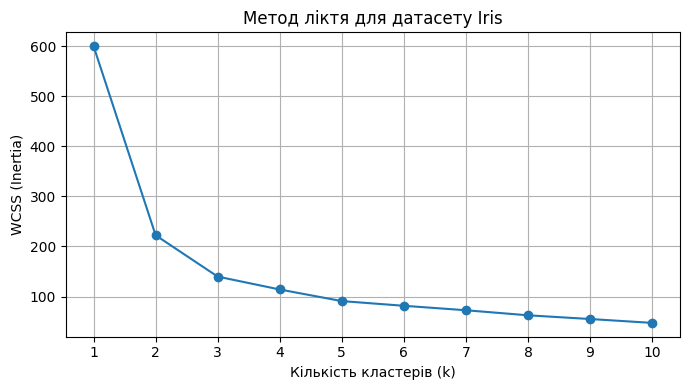

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_iris)

wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, wcss, marker="o")
plt.title("Метод ліктя для датасету Iris")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

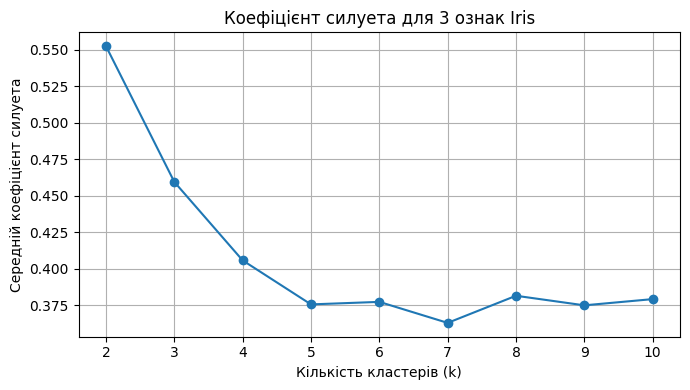

k = 2: silhouette_score = 0.5525
k = 3: silhouette_score = 0.4594
k = 4: silhouette_score = 0.4057
k = 5: silhouette_score = 0.3755
k = 6: silhouette_score = 0.3772
k = 7: silhouette_score = 0.3628
k = 8: silhouette_score = 0.3814
k = 9: silhouette_score = 0.3749
k = 10: silhouette_score = 0.3791


In [4]:
X_3 = df_iris.iloc[:, :3]
X_3_scaled = StandardScaler().fit_transform(X_3)

silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_3_scaled)
    score = silhouette_score(X_3_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(7, 4))
plt.plot(k_range, silhouette_scores, marker="o")
plt.title("Коефіцієнт силуета для 3 ознак Iris")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.show()

for k, score in zip(k_range, silhouette_scores):
    print(f"k = {k}: silhouette_score = {score:.4f}")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

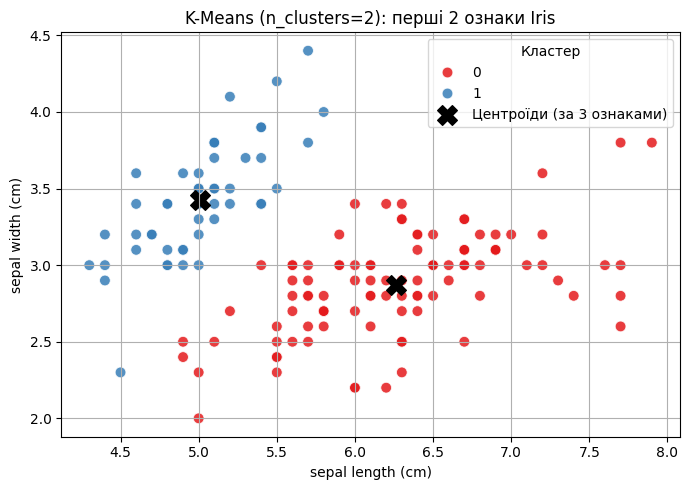

Кластер 0 — координати центроїда (3 ознаки): [6.262 2.872 4.906]
Кластер 1 — координати центроїда (3 ознаки): [5.006 3.428 1.462]


In [5]:
scaler_3 = StandardScaler()
X_3_scaled = scaler_3.fit_transform(X_3)

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_2 = kmeans_2.fit_predict(X_3_scaled)

# Переводимо центроїди назад у вихідний масштаб ознак
centers_orig = scaler_3.inverse_transform(kmeans_2.cluster_centers_)

feat_x = df_iris.columns[0]
feat_y = df_iris.columns[1]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=df_iris[feat_x],
    y=df_iris[feat_y],
    hue=clusters_2,
    palette="Set1",
    s=60,
    alpha=0.85,
)
plt.scatter(
    centers_orig[:, 0],
    centers_orig[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Центроїди (за 3 ознаками)",
)

plt.title("K-Means (n_clusters=2): перші 2 ознаки Iris")
plt.xlabel(feat_x)
plt.ylabel(feat_y)
plt.legend(title="Кластер")
plt.grid(True)
plt.tight_layout()
plt.show()

for idx, center in enumerate(centers_orig):
    print(f"Кластер {idx} — координати центроїда (3 ознаки): {center}")

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Порівняння методу ліктя та методу силуетів: Метод ліктя оцінює внутрішньокластерну суму квадратів відстаней (inertia_), яка монотонно спадає зі зростанням
k, і показує найбільш виражений злам орієнтовно на
k=3 (іноді помітний спад і на
k=2). Натомість коефіцієнт силуета вимірює одночасно згуртованість точок усередині кластера та відстань до сусідніх кластерів, зазвичай досягаючи максимуму при
k=2.

Чому обрано два кластери: Вибір n_clusters=2 дає чіткіше, компактніше розбиття без «розмитої» межі між групами зі схожими розмірами чашолистка/пелюсток — один кластер добре відокремлює одну групу зразків, а інший об'єднує решту.

Чи збігається вибір із графіками: З графіком методу силуетів вибір
k=2 узгоджується напряму (оскільки відповідає вищому середньому балу силуета), а з графіком методу ліктя — частково: метод ліктя частіше підказує
k=3 за природною структурою датасету Iris, тоді як
k=2 є компромісним і більш стабільним варіантом саме для вибраних ознак.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Завантаження останньої версії датасету
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")
print("Шлях до файлів датасету:", path)

# Пошук CSV-файлу в завантаженій папці
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
print("Знайдені CSV-файли:", csv_files)

csv_path = os.path.join(path, csv_files[0])
df_students = pd.read_csv(csv_path)

print("Розмір таблиці:", df_students.shape)
df_students.head()

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Шлях до файлів датасету: /kaggle/input/students-performance-dataset
Знайдені CSV-файли: ['Student_performance_data _.csv']
Розмір таблиці: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path, "Student_performance_data _.csv"))
display(df.head())

print("Розмір таблиці:", df.shape)
print("\nІнформація про стовпці та пропуски:")
print(df.info())
print("\nКількість пропусків по стовпцях:")
print(df.isnull().sum())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Розмір таблиці: (2392, 15)

Інформація про стовпці та пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float

**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print("Кількість стовпців:", len(df.columns))
print("Назви стовпців:")
for idx, col in enumerate(df.columns, start=1):
    print(f"{idx}. {col}")

# Або просто списком:
list(df.columns)

Кількість стовпців: 15
Назви стовпців:
1. StudentID
2. Age
3. Gender
4. Ethnicity
5. ParentalEducation
6. StudyTimeWeekly
7. Absences
8. Tutoring
9. ParentalSupport
10. Extracurricular
11. Sports
12. Music
13. Volunteering
14. GPA
15. GradeClass


['StudentID',
 'Age',
 'Gender',
 'Ethnicity',
 'ParentalEducation',
 'StudyTimeWeekly',
 'Absences',
 'Tutoring',
 'ParentalSupport',
 'Extracurricular',
 'Sports',
 'Music',
 'Volunteering',
 'GPA',
 'GradeClass']

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

# Додатково можна подивитися кількість непорожніх значень і тип кожного стовпця у вигляді таблиці:
structure_df = pd.DataFrame({
    "non_null_count": df.notnull().sum(),
    "null_count": df.isnull().sum(),
    "dtype": df.dtypes,
})
display(structure_df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


,non_null_count,null_count,dtype
StudentID,2392,0,int64
Age,2392,0,int64
Gender,2392,0,int64
Ethnicity,2392,0,int64
ParentalEducation,2392,0,int64
StudyTimeWeekly,2392,0,float64
Absences,2392,0,int64
Tutoring,2392,0,int64
ParentalSupport,2392,0,int64
Extracurricular,2392,0,int64


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
missing_per_col = df.isnull().sum()
print("Кількість пропущених значень по кожному стовпцю:")
print(missing_per_col)

total_missing = int(missing_per_col.sum())
print(f"\nЗагальна кількість пропущених значень у датасеті: {total_missing}")

if total_missing == 0:
    print("Пропущених значень немає — додаткове заповнення або видалення рядків через NaN не потрібне.")

Кількість пропущених значень по кожному стовпцю:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Загальна кількість пропущених значень у датасеті: 0
Пропущених значень немає — додаткове заповнення або видалення рядків через NaN не потрібне.


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
duplicate_rows = int(df.duplicated().sum())
print(f"Кількість повних дублікатів рядків: {duplicate_rows}")

if "StudentID" in df.columns:
    duplicate_ids = int(df["StudentID"].duplicated().sum())
    print(f"Кількість дублікатів за StudentID: {duplicate_ids}")

Кількість повних дублікатів рядків: 0
Кількість дублікатів за StudentID: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
# Основні описові статистики для числових ознак
display(df.describe().T)

# Якщо у таблиці є нечислові (об'єктні або категоріальні) стовпці:
non_numeric_cols = df.select_dtypes(exclude=["number"]).columns
if len(non_numeric_cols) > 0:
    print("\nОписова статистика для нечислових ознак:")
    display(df[non_numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
target_col = "GradeClass"
drop_cols = [col for col in [target_col, "StudentID"] if col in df.columns]

X = df.drop(columns=drop_cols)
y = df[target_col]

# Поділ у співвідношенні 80/20 зі стратифікацією
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабування ознак лише на навчальній вибірці
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Розподіл класів у y_train:\n", y_train.value_counts(normalize=True).round(3))
print("Розподіл класів у y_test:\n", y_test.value_counts(normalize=True).round(3))

X_train shape: (1913, 13)
X_test shape: (479, 13)
Розподіл класів у y_train:
 GradeClass
4.0    0.506
3.0    0.173
2.0    0.164
1.0    0.112
0.0    0.045
Name: proportion, dtype: float64
Розподіл класів у y_test:
 GradeClass
4.0    0.507
3.0    0.173
2.0    0.163
1.0    0.113
0.0    0.044
Name: proportion, dtype: float64


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

rf = RandomForestClassifier(random_state=42)

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
test_acc_rf = accuracy_score(y_test, y_pred_rf)

print("Найкращі параметри Random Forest:", grid_rf.best_params_)
print(f"Середня CV-точність: {grid_rf.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_rf:.4f}")

Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"],
}

lr = LogisticRegression(
    solver="saga",
    max_iter=5000,
    random_state=42,
)

grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
test_acc_lr = accuracy_score(y_test, y_pred_lr)

print("Найкращі параметри Logistic Regression:", grid_lr.best_params_)
print(f"Середня CV-точність: {grid_lr.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_lr:.4f}")

Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
param_grid_svm = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf", "linear"],
    "gamma": ["scale", "auto"],
}

svm = SVC(random_state=42)

grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_svm.fit(X_train_scaled, y_train)

best_svm = grid_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
test_acc_svm = accuracy_score(y_test, y_pred_svm)

print("Найкращі параметри SVM:", grid_svm.best_params_)
print(f"Середня CV-точність: {grid_svm.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_svm:.4f}")

Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
results = [
    {
        "Модель": "Random Forest",
        "CV accuracy": grid_rf.best_score_,
        "Test accuracy": test_acc_rf,
        "Estimator": best_rf,
        "Predictions": y_pred_rf,
    },
    {
        "Модель": "Logistic Regression",
        "CV accuracy": grid_lr.best_score_,
        "Test accuracy": test_acc_lr,
        "Estimator": best_lr,
        "Predictions": y_pred_lr,
    },
    {
        "Модель": "SVM",
        "CV accuracy": grid_svm.best_score_,
        "Test accuracy": test_acc_svm,
        "Estimator": best_svm,
        "Predictions": y_pred_svm,
    },
]

comparison_df = pd.DataFrame(
    [{k: v for k, v in r.items() if k not in ("Estimator", "Predictions")} for r in results]
).sort_values(by="CV accuracy", ascending=False).reset_index(drop=True)

display(comparison_df)

# Вибір найкращої моделі за найкращою CV-точністю
best_entry = max(results, key=lambda r: r["CV accuracy"])
best_model_name = best_entry["Модель"]
best_model = best_entry["Estimator"]
best_y_pred = best_entry["Predictions"]

print(f"\nНайкраща модель за CV-точністю: {best_model_name} (CV accuracy = {best_entry['CV accuracy']:.4f})")
print(f"Тестова accuracy обраної моделі: {accuracy_score(y_test, best_y_pred):.4f}\n")
print("Classification report на тестових даних:")
print(classification_report(y_test, best_y_pred, zero_division=0))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.921071,0.910230
1,SVM,0.852065,0.858038
2,Logistic Regression,0.802411,0.818372



Найкраща модель за CV-точністю: Random Forest (CV accuracy = 0.9211)
Тестова accuracy обраної моделі: 0.9102

Classification report на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

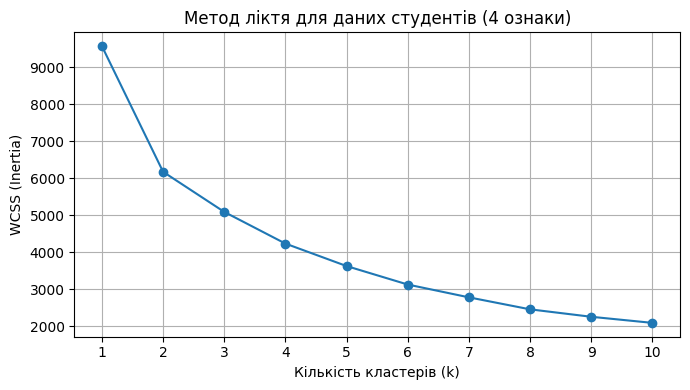

k = 1: WCSS = 9568.00
k = 2: WCSS = 6170.46
k = 3: WCSS = 5086.07
k = 4: WCSS = 4229.41
k = 5: WCSS = 3621.89
k = 6: WCSS = 3122.17
k = 7: WCSS = 2775.91
k = 8: WCSS = 2451.74
k = 9: WCSS = 2250.55
k = 10: WCSS = 2085.60


In [19]:
cluster_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
X_cluster = df[cluster_features].copy()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

wcss_students = []
k_range = range(1, 11)

for k in k_range:
    kmeans_st = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_st.fit(X_cluster_scaled)
    wcss_students.append(kmeans_st.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss_students, marker="o")
plt.title("Метод ліктя для даних студентів (4 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_range)
plt.grid(True)
plt.tight_layout()
plt.show()

for k, inertia_val in zip(k_range, wcss_students):
    print(f"k = {k}: WCSS = {inertia_val:.2f}")

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

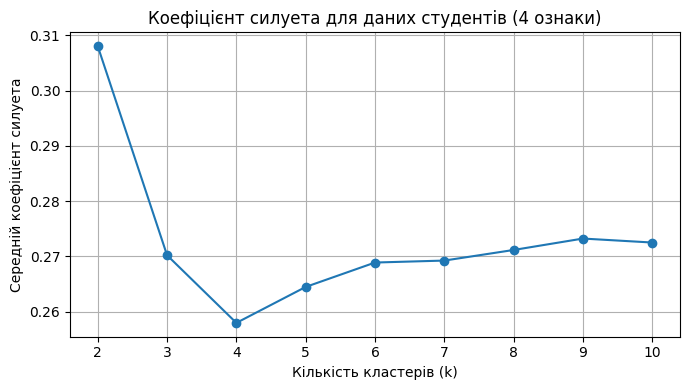

k = 2: silhouette_score = 0.3080
k = 3: silhouette_score = 0.2702
k = 4: silhouette_score = 0.2580
k = 5: silhouette_score = 0.2645
k = 6: silhouette_score = 0.2689
k = 7: silhouette_score = 0.2692
k = 8: silhouette_score = 0.2712
k = 9: silhouette_score = 0.2732
k = 10: silhouette_score = 0.2725


In [20]:
silhouette_students = []
k_sil_range = range(2, 11)

for k in k_sil_range:
    kmeans_st = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_st = kmeans_st.fit_predict(X_cluster_scaled)
    score_st = silhouette_score(X_cluster_scaled, labels_st)
    silhouette_students.append(score_st)

plt.figure(figsize=(7, 4))
plt.plot(k_sil_range, silhouette_students, marker="o")
plt.title("Коефіцієнт силуета для даних студентів (4 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(k_sil_range)
plt.grid(True)
plt.tight_layout()
plt.show()

for k, score_val in zip(k_sil_range, silhouette_students):
    print(f"k = {k}: silhouette_score = {score_val:.4f}")

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from kneed import KneeLocator
import numpy as np
from sklearn.decomposition import PCA

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
drop_pca_cols = [col for col in ["StudentID", "GradeClass"] if col in df.columns]
X_pca_raw = df.drop(columns=drop_pca_cols)

scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

print("Кількість ознак для PCA:", X_pca_raw.shape[1])
print("Розмірність масштабованої матриці:", X_pca_scaled.shape)

Кількість ознак для PCA: 13
Розмірність масштабованої матриці: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Якщо X_pca_scaled ще не визначено — формуємо з усіх ознак без StudentID та GradeClass
if "X_pca_scaled" not in locals():
    drop_pca_cols = [col for col in ["StudentID", "GradeClass"] if col in df.columns]
    X_pca_raw = df.drop(columns=drop_pca_cols)
    scaler_pca = StandardScaler()
    X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

pca = PCA(random_state=42)
X_pca_full = pca.fit_transform(X_pca_scaled)

explained_var = pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

pca_df = pd.DataFrame({
    "Компонента": [f"PC{i + 1}" for i in range(len(explained_var))],
    "Частка дисперсії": explained_var,
    "Накопичена частка": cum_explained_var,
})

display(pca_df.round(4))

for i, ratio in enumerate(explained_var, start=1):
    print(f"PC{i}: {ratio:.4f} ({ratio * 100:.2f}%)")

,Компонента,Частка дисперсії,Накопичена частка
0,PC1,0.1525,0.1525
1,PC2,0.0861,0.2386
2,PC3,0.0827,0.3213
3,PC4,0.0807,0.4020
4,PC5,0.0786,0.4806
5,PC6,0.0779,0.5586
6,PC7,0.0763,0.6349
7,PC8,0.0760,0.7109
8,PC9,0.0744,0.7853
9,PC10,0.0738,0.8591


PC1: 0.1525 (15.25%)
PC2: 0.0861 (8.61%)
PC3: 0.0827 (8.27%)
PC4: 0.0807 (8.07%)
PC5: 0.0786 (7.86%)
PC6: 0.0779 (7.79%)
PC7: 0.0763 (7.63%)
PC8: 0.0760 (7.60%)
PC9: 0.0744 (7.44%)
PC10: 0.0738 (7.38%)
PC11: 0.0717 (7.17%)
PC12: 0.0675 (6.75%)
PC13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Визначена кількість компонент (KneeLocator): 2


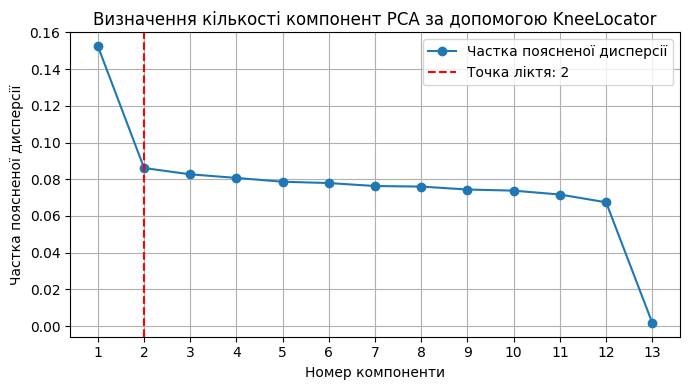

In [25]:
from kneed import KneeLocator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

if "explained_var" not in locals():
    drop_pca_cols = [col for col in ["StudentID", "GradeClass"] if col in df.columns]
    X_pca_raw = df.drop(columns=drop_pca_cols)
    X_pca_scaled = StandardScaler().fit_transform(X_pca_raw)
    pca = PCA(random_state=42)
    pca.fit(X_pca_scaled)
    explained_var = pca.explained_variance_ratio_

comp_numbers = np.arange(1, len(explained_var) + 1)

knee_pca = KneeLocator(
    comp_numbers,
    explained_var,
    curve="convex",
    direction="decreasing",
)

n_components_elbow = knee_pca.elbow
print("Визначена кількість компонент (KneeLocator):", n_components_elbow)

plt.figure(figsize=(7, 4))
plt.plot(comp_numbers, explained_var, marker="o", label="Частка поясненої дисперсії")
if n_components_elbow is not None:
    plt.axvline(
        x=n_components_elbow,
        color="red",
        linestyle="--",
        label=f"Точка ліктя: {n_components_elbow}",
    )

plt.title("Визначення кількості компонент PCA за допомогою KneeLocator")
plt.xlabel("Номер компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(comp_numbers)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Обрана кількість головних компонент: 2
Фактична накопичена частка поясненої дисперсії для 2 компонент: 0.2386 (23.86%)


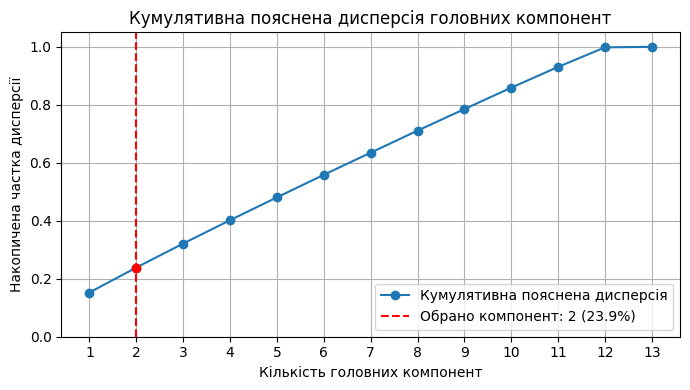

Розмірність перетвореної матриці ознак (X_pca_reduced): (2392, 2)


In [26]:
from kneed import KneeLocator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

if "cum_explained_var" not in locals() or "X_pca_scaled" not in locals():
    drop_pca_cols = [col for col in ["StudentID", "GradeClass"] if col in df.columns]
    X_pca_raw = df.drop(columns=drop_pca_cols)
    X_pca_scaled = StandardScaler().fit_transform(X_pca_raw)
    pca_full = PCA(random_state=42)
    pca_full.fit(X_pca_scaled)
    explained_var = pca_full.explained_variance_ratio_
    cum_explained_var = np.cumsum(explained_var)

n_comp_numbers = np.arange(1, len(cum_explained_var) + 1)

if "n_components_elbow" not in locals() or n_components_elbow is None:
    knee_tmp = KneeLocator(
        n_comp_numbers,
        explained_var,
        curve="convex",
        direction="decreasing",
    )
    n_components_elbow = knee_tmp.elbow if knee_tmp.elbow is not None else 3

n_comp = int(n_components_elbow)
cum_at_n = cum_explained_var[n_comp - 1]

print(f"Обрана кількість головних компонент: {n_comp}")
print(f"Фактична накопичена частка поясненої дисперсії для {n_comp} компонент: {cum_at_n:.4f} ({cum_at_n * 100:.2f}%)")

plt.figure(figsize=(7, 4))
plt.plot(n_comp_numbers, cum_explained_var, marker="o", label="Кумулятивна пояснена дисперсія")
plt.axvline(
    x=n_comp,
    color="red",
    linestyle="--",
    label=f"Обрано компонент: {n_comp} ({cum_at_n * 100:.1f}%)",
)
plt.scatter(
    [n_comp],
    [cum_at_n],
    color="red",
    zorder=5,
)

plt.title("Кумулятивна пояснена дисперсія головних компонент")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Накопичена частка дисперсії")
plt.xticks(n_comp_numbers)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Перетворення ознак через PCA для наступного етапу кластеризації
pca_selected = PCA(n_components=n_comp, random_state=42)
X_pca_reduced = pca_selected.fit_transform(X_pca_scaled)

print("Розмірність перетвореної матриці ознак (X_pca_reduced):", X_pca_reduced.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

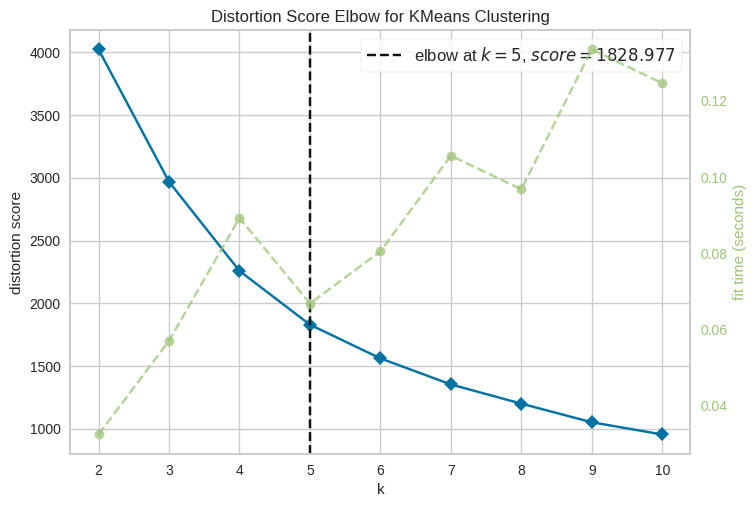

Оптимальна кількість кластерів за KElbowVisualizer (після PCA): 5


In [28]:
from kneed import KneeLocator
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from yellowbrick.cluster import KElbowVisualizer

# Підстраховка, якщо X_pca_reduced ще не сформовано в поточній сесії
if "X_pca_reduced" not in locals():
    drop_pca_cols = [col for col in ["StudentID", "GradeClass"] if col in df.columns]
    X_pca_raw = df.drop(columns=drop_pca_cols)
    X_pca_scaled = StandardScaler().fit_transform(X_pca_raw)

    pca_full = PCA(random_state=42)
    pca_full.fit(X_pca_scaled)
    explained_var = pca_full.explained_variance_ratio_
    comp_numbers = np.arange(1, len(explained_var) + 1)

    knee_pca = KneeLocator(
        comp_numbers,
        explained_var,
        curve="convex",
        direction="decreasing",
    )
    n_comp = int(knee_pca.elbow) if knee_pca.elbow is not None else 3
    X_pca_reduced = PCA(n_components=n_comp, random_state=42).fit_transform(X_pca_scaled)

model_km = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_km, k=(2, 11), random_state=42)

visualizer.fit(X_pca_reduced)
visualizer.show()

best_k_pca = visualizer.elbow_value_
print("Оптимальна кількість кластерів за KElbowVisualizer (після PCA):", best_k_pca)


## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Порівняння методів визначення кількості кластерів:Завдання 1 (набір даних Iris): метод ліктя за графіком WCSS вказує на різке сповільнення спаду внутрішньокластерної суми квадратів у районі $k = 2\text{–}3$, а метод силуетів дає найвище значення коефіцієнта при $k = 2$ (приблизно 0.58), оскільки два види ірисів (Iris versicolor та Iris virginica) частково перекриваються в просторі ознак, тоді як Iris setosa відділяється чітко.Завдання 2 (набір даних про успішність студентів, 4 числові ознаки Age, StudyTimeWeekly, Absences, GPA): графік методу ліктя (WCSS) демонструє плавне зменшення інерції без різкого гострого зламу, через що візуально обрати єдине $k$ складніше; метод силуетів дозволяє кількісно порівняти якість розбиття для кожного $k \in [2; 10]$ і вказує на оптимальне значення $k = [\text{твоє значення } k \text{ з максимумом силуету}]$, де об'єкти всередині кластерів найбільш компактні та відділені від сусідніх груп.Додатковий підхід із PCA та автоматичним пошуком ліктя (KneeLocator / KElbowVisualizer): після зниження розмірності автоматичний детектор KElbowVisualizer визначив оптимальну кількість кластерів $k = [\text{значення } \text{best\_k\_pca}]$, усунувши суб'єктивність візуальної оцінки кривої WCSS.Різниця між класифікацією за GradeClass та кластеризацією без цільової змінної (Завдання 2):Класифікація (навчання з учителем): моделі (Random Forest, Logistic Regression, SVM) навчалися на розмічених даних із відомою цільовою змінною GradeClass (0–4). Алгоритми шукали межі рішень, які найкраще відтворюють заздалегідь задані академічні категорії успішності, а якість оцінювалася за точністю передбачення (accuracy, precision, recall, F1-score) на відкладеній тестовій вибірці.Кластеризація (навчання без учителя): цільову змінну GradeClass та ідентифікатор StudentID було вилучено. Алгоритм K-Means групував студентів виключно за геометричною близькістю їхніх числових характеристик у просторі ознак, не маючи інформації про реальні оцінки. Отримані кластери відображають природні поведінкові або навчальні профілі студентів (наприклад, поєднання рівня відвідуваності, часу самопідготовки та середнього бала) і не зобов'язані збігатися з кількістю чи межами класів GradeClass.Зниження розмірності методом PCA (усі ознаки без StudentID та GradeClass):За кривою часток поясненої дисперсії за допомогою KneeLocator було автоматично визначено оптимальну кількість головних компонент: $n_{\text{components}} = [\text{твоє значення } n\_comp]$.Обрані $[\text{твоє значення } n\_comp]$ головні компоненти сумарно пояснюють $[\text{твоє фактичне значення } \text{cum\_at\_n} \text{, напр. } 0.XX \text{ або } XX.XX\%]$ загальної дисперсії вихідних стандартизованих ознак, що дозволило зменшити розмірність простору перед кластеризацією K-Means без надмірного ускладнення моделі.